# 02 Portfolio evaluation

**Question: do forecast gains translate into better risk-adjusted performance in
volatility-managed portfolios?** This notebook answers it block by block. Each block in
`BLOCKS` (`models/research_config.py`) asks one sub-question of the research question, such as
"does macro help within GARCH?" or "is VIX doing all the work?", and is answered on the portfolio
side here, with the same pairs the forecast evaluation tests with Diebold-Mariano.

Every managed portfolio built in `p1_build_portfolios.ipynb` is compared with **two benchmarks**,
and the models within each block are compared **with each other**:

| Comparison | Question it answers |
|---|---|
| model vs **buy-and-hold (BH)** | Does volatility timing with this forecast work at all? |
| model vs **`hist_rw`** | Does this forecast add anything beyond the simplest volatility timing (Moreira & Muir: σ̂²ₜ₊₁ = RVₜ)? |
| model a vs model b, within a block | Does the addition in a (macro, VIX, non-linearity) give a better portfolio? |

**Layout.** Part A is the cyclical bucket, the headline: an overview, then one section per block,
then a scoreboard. Part B repeats the comparisons for each ETF on its own. Part C checks that the
conclusions hold under the expanding σ̄² and separates timing from re-levering.

The interpretation of the results is in `interpretation.md`, in this folder, for the report.

## Setup

In [39]:
import sys
from pathlib import Path

_checkout = next(
    (p for p in (Path.cwd(), *Path.cwd().parents)
     if (p / "models" / "research_config.py").is_file()),
    None,
)
if _checkout is None:
    raise FileNotFoundError("Start the notebook kernel from within this project checkout.")
sys.path.insert(0, str(_checkout / "models"))
from utils.paths import PROJECT_ROOT, MODELS_DIR, DATASET_DIR, FORECAST_DIR, FORECAST_RESULTS_DIR

import sys
import json
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display



from research_config import BLOCKS
from utils.portfolio_utils import (
    BH, CONTROL, PORTFOLIO_DIR, EVAL_DIR, load_portfolios,
    performance_row, evaluate_bucket, alpha_regression, alpha_vs_bh_and_control,
    compare_pair, per_etf_table, pct_capped, pct_capped_pooled,
    block_models, stars, outcome, verdict, plot_growth, heatmap,
)

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 60)
pd.set_option("display.float_format", "{:.3f}".format)

### Load the saved portfolios

The models, comparison pairs, specifications and cap come from `results/portfolios/run_info.json`,
so this notebook always matches the latest run of `p1_build_portfolios.ipynb`. Pairs whose models
were not built are listed and left out.

In [40]:
run_info = json.loads((PORTFOLIO_DIR / "run_info.json").read_text())
MODELS, SPECS, K_CAP = run_info["variants"], run_info["specs"], run_info["k_cap"]
MAIN_SPEC, BENCHMARK = run_info["main_spec"], run_info["benchmark"]
ROBUST_SPEC = next(s for s in SPECS if s != MAIN_SPEC)
pairs = pd.DataFrame(run_info["pairs"]).set_index("pair")
skipped = pd.DataFrame(run_info["skipped_pairs"], columns=["pair", "block", "a", "b", "isolates", "missing"])

portfolios = {}
for spec in SPECS:
    portfolios[spec], xret = load_portfolios(spec)
    assert set(MODELS) <= set(portfolios[spec]), f"{spec}: saved models do not match run_info"
TICKERS = list(xret.columns)
bh = xret.mean(axis=1)

print("Models:", MODELS)
print(f"Benchmark: {BENCHMARK} | specifications: {SPECS} (main: {MAIN_SPEC})")
print(f"Out-of-sample window: {run_info['oos_window'][0]} to {run_info['oos_window'][1]}"
      f" ({len(xret)} months)")
print(f"\n{len(pairs)} pairs tested. Skipped (models not built yet):")
skipped

Models: ['hist_rw', 'garch', 'garch_midas_baa10y', 'en_no_macro', 'en_no_vix', 'en_vix_only', 'en_full_macro', 'xgb_no_macro', 'xgb_no_vix', 'xgb_vix_only', 'xgb_full_macro']
Benchmark: hist_rw | specifications: ['fixed', 'expanding'] (main: fixed)
Out-of-sample window: 2008-03 to 2025-12 (214 months)

14 pairs tested. Skipped (models not built yet):


,pair,block,a,b,isolates,missing


## Evaluation measures

The functions are in `utils/portfolio_utils.py`:

- **Performance** (`performance_row`): annualised mean and volatility of monthly excess returns,
  annualised Sharpe ratio (SR), maximum drawdown of the cumulative excess-return series, and
  average monthly turnover mean_t Σᵢ |wᵢ,ₜ − wᵢ,ₜ₋₁| over the weight held in each ETF. Buy-and-hold
  holds fixed weights, so its turnover is 0 by this measure.
- **Ledoit & Wolf (2008)** (`ledoit_wolf_sharpe_test`): tests H₀: SR(x) = SR(y) with the
  studentised circular block bootstrap (block 5, 5,000 draws). The two portfolios are tested
  directly, so the test uses their correlation: two models can both be insignificant against BH
  and still differ from each other, or the reverse. Sharpe ratios are tested on monthly data and
  reported annualised.
- **Alpha** (`alpha_regression`): f^σ_t = α + β · BH_t + εₜ with Newey-West standard errors
  (lag ⌊4(T/100)^{2/9}⌋ = 4). α is reported annualised.
- **% capped**: the share of ETF-months in which the base weight is at the cap k = 2.

Every managed portfolio is rescaled to the volatility of buy-and-hold, so mean returns, alphas
and drawdowns are compared at the same risk.

**Sign convention.** Each pair is (a, b), with a the richer model. ΔSR = SR(a) − SR(b), so a
positive ΔSR means the addition helps. Stars: \*\*\* p < 0.01, \*\* p < 0.05, \* p < 0.10.

## Run every test

One cell computes every test, so the sections below only display results (about 75 seconds):

1. every model against BH: performance, Ledoit-Wolf and alpha, for the bucket and each ETF;
2. Ledoit-Wolf tests of every model against `hist_rw` and of every block pair, for the bucket and
   each ETF.

Both under each σ̄² specification.

In [41]:
t0 = time.time()
bh_weights = pd.DataFrame(1 / len(TICKERS), index=xret.index, columns=TICKERS)

vs_bh, vs_bh_etf = {}, {}
for spec in SPECS:
    res = portfolios[spec]
    tbl = pd.DataFrame({BH: performance_row(bh, bh_weights)}
                       | {m: evaluate_bucket(res[m], bh) for m in MODELS}).T
    tbl["pct_capped"] = pd.Series({m: pct_capped_pooled(res[m]["weights_base"], K_CAP) for m in MODELS})
    vs_bh[spec] = tbl.rename_axis("portfolio")
    vs_bh_etf[spec] = pd.concat(
        {m: per_etf_table(res[m], xret).assign(pct_capped=pct_capped(res[m]["weights_base"], K_CAP))
         for m in MODELS},
        names=["model", "ETF"])

# Each model against the benchmark, then the block pairs (B0's pairs are already in the first list)
tests = list(dict.fromkeys([(m, BENCHMARK) for m in MODELS if m != BENCHMARK]
                           + list(zip(pairs["a"], pairs["b"]))))
lw = pd.concat({(spec, a, b): compare_pair(portfolios[spec][a], portfolios[spec][b], xret)
                for spec in SPECS for a, b in tests},
               names=["spec", "a", "b"])[["SR_a", "SR_b", "SR_diff", "LW_t", "LW_p"]].astype(float).sort_index()
print(f"Done in {time.time() - t0:.0f}s: {len(tests)} model pairs, {len(MODELS)} models vs BH, "
      f"bucket + {len(TICKERS)} ETFs, {len(SPECS)} specifications")

Done in 108s: 23 model pairs, 11 models vs BH, bucket + 5 ETFs, 2 specifications


Helpers that lay out each block's tables, plot and verdicts from the results above.

In [42]:
def bench_table(models, spec=MAIN_SPEC):
    # BH, the benchmark and `models`: SR, tests against BH and the benchmark, risk, robustness
    rows = [BH, BENCHMARK] + [m for m in models if m != BENCHMARK]
    main, rob = vs_bh[spec], vs_bh[ROBUST_SPEC]
    vs_rw = lw.loc[spec].xs("Cyclical", level="ETF")
    rw = lambda m, col: vs_rw.at[(m, BENCHMARK), col] if (m, BENCHMARK) in vs_rw.index else np.nan
    return pd.DataFrame({
        "SR": main.loc[rows, "ann_sharpe"],
        "ΔSR vs BH": main.loc[rows, "SR_diff_vs_BH"],
        "p vs BH": main.loc[rows, "LW_p"],
        "α % p.a.": main.loc[rows, "alpha_annual"] * 100,
        "α t": main.loc[rows, "alpha_t"],
        f"ΔSR vs {BENCHMARK}": [rw(m, "SR_diff") for m in rows],
        f"p vs {BENCHMARK}": [rw(m, "LW_p") for m in rows],
        "MaxDD %": main.loc[rows, "max_drawdown"] * 100,
        "turnover": main.loc[rows, "avg_turnover"],
        "% capped": main.loc[rows, "pct_capped"],
        f"SR ({ROBUST_SPEC})": rob.loc[rows, "ann_sharpe"],
        f"p vs BH ({ROBUST_SPEC})": rob.loc[rows, "LW_p"],
    }, index=rows).rename_axis("portfolio")


def pair_rows(block_id=None, unit="Cyclical"):
    # One row per pair: the Ledoit-Wolf test under both specifications
    sub = pairs if block_id is None else pairs[pairs["block"] == block_id]
    rows = {}
    for pid, p in sub.iterrows():
        m, r = lw.loc[(MAIN_SPEC, p.a, p.b, unit)], lw.loc[(ROBUST_SPEC, p.a, p.b, unit)]
        rows[pid] = {
            "block": p.block, "a": p.a, "b": p.b, "isolates": p.isolates,
            "SR_a": m.SR_a, "SR_b": m.SR_b, "ΔSR": m.SR_diff, "LW t": m.LW_t, "p": m.LW_p,
            "sig": stars(m.LW_p), "result": outcome(m.SR_diff, m.LW_p),
            f"ΔSR ({ROBUST_SPEC})": r.SR_diff, f"p ({ROBUST_SPEC})": r.LW_p,
            f"result ({ROBUST_SPEC})": outcome(r.SR_diff, r.LW_p),
            "same sign": bool(np.sign(m.SR_diff) == np.sign(r.SR_diff)),
        }
    return pd.DataFrame(rows).T.rename_axis("pair")


def show_block(block_id):
    block = BLOCKS[block_id]
    models = block_models(block, MODELS)
    print(f"{block_id} {block['title']}: {block['question']}")
    print(f"\nBucket portfolios against the benchmarks ({MAIN_SPEC} σ̄²; last two columns: {ROBUST_SPEC}):")
    display(bench_table(models))

    tbl = pair_rows(block_id)
    print(f"\nPair tests, SR(a) = SR(b):")
    display(tbl.drop(columns="block"))
    for pid, r in tbl.iterrows():
        print(verdict(pid, r.a, r.b, r["ΔSR"], r.p)
              + f"   [{ROBUST_SPEC}: ΔSR {r[f'ΔSR ({ROBUST_SPEC})']:+.3f}, p = {r[f'p ({ROBUST_SPEC})']:.3f}]")
    for pid, s in skipped[skipped["block"] == block_id].iterrows():
        print(f"{s.pair}: skipped, {s.missing} not built yet ({s.a} vs {s.b})")

    # Growth of $1: one panel, or one panel per pair when the block has many models
    main = portfolios[MAIN_SPEC]
    panels = ([(f"{block_id}: growth of $1, {MAIN_SPEC} σ̄²", [m for m in models if m != BENCHMARK])]
              if len(models) <= 4 else
              [(f"{pid}: {p.a} vs {p.b}", [p.b, p.a]) for pid, p in pairs[pairs["block"] == block_id].iterrows()])
    ncols = min(len(panels), 2)
    nrows = int(np.ceil(len(panels) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(7 * ncols, 3.8 * nrows), squeeze=False, sharey=True)
    for ax, (title, ms) in zip(axes.flat, panels):
        returns = pd.DataFrame({BH: bh, BENCHMARK: main[BENCHMARK]["managed"]}
                               | {m: main[m]["managed"] for m in ms})
        plot_growth(returns, ax, title, benchmark=BENCHMARK)
    for ax in axes.flat[len(panels):]:
        ax.set_visible(False)
    fig.tight_layout()
    plt.show()

# Part A: Cyclical bucket

## A.0 Overview: every portfolio against the two benchmarks

The volatility-managed cyclical bucket from each model, under the fixed σ̄². This answers the
first-order question, does volatility timing beat buy-and-hold, before the blocks ask which
forecast gives the better portfolio.

In [43]:
overview = bench_table(MODELS)
overview

,SR,ΔSR vs BH,p vs BH,α % p.a.,α t,ΔSR vs hist_rw,p vs hist_rw,MaxDD %,turnover,% capped,SR (expanding),p vs BH (expanding)
portfolio,,,,,,,,,,,,
BH,0.476,NaN,NaN,NaN,NaN,NaN,NaN,-55.519,0.000,NaN,0.476,NaN
hist_rw,0.468,-0.008,0.969,2.175,0.644,NaN,NaN,-50.558,0.493,21.308,0.603,0.520
garch,0.497,0.021,0.912,2.449,0.787,0.029,0.469,-45.791,0.410,4.393,0.608,0.489
garch_midas_baa10y,0.499,0.023,0.904,2.462,0.787,0.031,0.458,-45.579,0.404,4.299,0.610,0.483
en_no_macro,0.454,-0.022,0.914,1.625,0.505,-0.014,0.675,-52.705,0.499,5.327,0.593,0.532
en_no_vix,0.416,-0.060,0.764,0.787,0.242,-0.052,0.389,-55.741,0.369,4.766,0.550,0.679
en_vix_only,0.451,-0.025,0.895,1.586,0.495,-0.017,0.685,-50.419,0.390,2.991,0.559,0.667
en_full_macro,0.399,-0.077,0.691,0.613,0.194,-0.069,0.230,-52.151,0.338,3.271,0.539,0.725
xgb_no_macro,0.361,-0.115,0.511,-0.715,-0.245,-0.107,0.117,-55.092,0.311,1.028,0.510,0.839


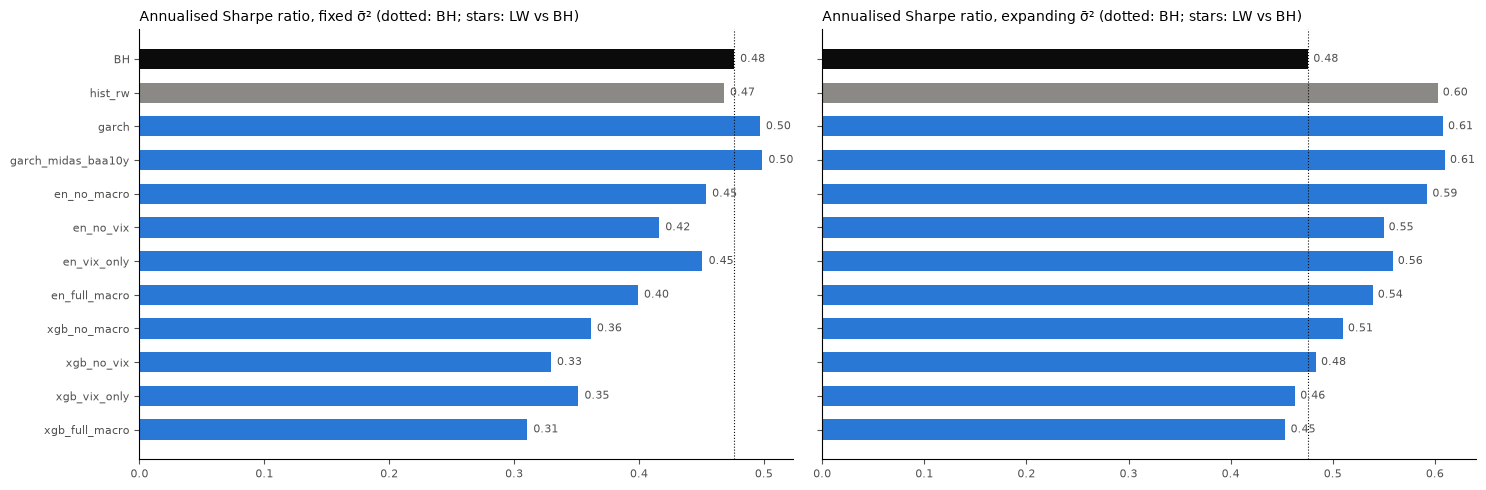

In [44]:
fig, axes = plt.subplots(1, len(SPECS), figsize=(15, 5), sharey=True, squeeze=False)
for ax, spec in zip(axes.flat, SPECS):
    sr = vs_bh[spec].loc[[BH] + MODELS, "ann_sharpe"]
    colors = ["#0b0b0b" if m == BH else "#8a8985" if m == BENCHMARK else "#2a78d6" for m in sr.index]
    ax.barh(sr.index[::-1], sr.values[::-1], color=colors[::-1], height=0.6)
    ax.axvline(sr[BH], color="#0b0b0b", linewidth=0.8, linestyle=":")
    for i, (m, v) in enumerate(sr[::-1].items()):
        ax.text(v + 0.005, i, f"{v:.2f}{stars(vs_bh[spec].at[m, 'LW_p']) if m != BH else ''}",
                va="center", fontsize=8, color="#52514e")
    ax.set_title(f"Annualised Sharpe ratio, {spec} σ̄² (dotted: BH; stars: LW vs BH)", fontsize=10, loc="left")
    ax.tick_params(labelsize=8, colors="#52514e")
    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)
fig.tight_layout()
plt.show()

## A.1 B0: Volatility-timing baseline

**Question: Does the simplest volatility timing beat buy-and-hold, and does fitting a historical-volatility model improve on it?**

| Pair | a | b | Isolates |
|---|---|---|---|
| B0.1 | `garch` | `hist_rw` | fitted GARCH vs naive history |

B0 Volatility-timing baseline: Does the simplest volatility timing beat buy-and-hold, and does fitting a historical-volatility model improve on it?

Bucket portfolios against the benchmarks (fixed σ̄²; last two columns: expanding):


,SR,ΔSR vs BH,p vs BH,α % p.a.,α t,ΔSR vs hist_rw,p vs hist_rw,MaxDD %,turnover,% capped,SR (expanding),p vs BH (expanding)
portfolio,,,,,,,,,,,,
BH,0.476,NaN,NaN,NaN,NaN,NaN,NaN,-55.519,0.000,NaN,0.476,NaN
hist_rw,0.468,-0.008,0.969,2.175,0.644,NaN,NaN,-50.558,0.493,21.308,0.603,0.520
garch,0.497,0.021,0.912,2.449,0.787,0.029,0.469,-45.791,0.410,4.393,0.608,0.489



Pair tests, SR(a) = SR(b):


,a,b,isolates,SR_a,SR_b,ΔSR,LW t,p,sig,result,ΔSR (expanding),p (expanding),result (expanding),same sign
pair,,,,,,,,,,,,,,
B0.1,garch,hist_rw,fitted GARCH vs naive history,0.497,0.468,0.029,0.736,0.469,,n.s.,0.005,0.894,n.s.,True


B0.1: no significant difference between garch and hist_rw (ΔSR +0.029, p = 0.469)   [expanding: ΔSR +0.005, p = 0.894]


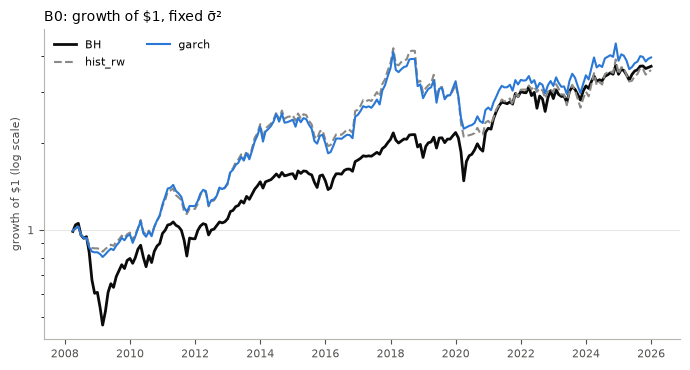

In [45]:
show_block("B0")

## A.2 B1: GARCH family

**Question: Does macro information help within the GARCH family?**

| Pair | a | b | Isolates |
|---|---|---|---|
| B1.1 | `garch_midas_baa10y` | `garch` | credit spread (BAA10Y) as the long-run component |

B1 GARCH family: Does macro information help within the GARCH family?

Bucket portfolios against the benchmarks (fixed σ̄²; last two columns: expanding):


,SR,ΔSR vs BH,p vs BH,α % p.a.,α t,ΔSR vs hist_rw,p vs hist_rw,MaxDD %,turnover,% capped,SR (expanding),p vs BH (expanding)
portfolio,,,,,,,,,,,,
BH,0.476,NaN,NaN,NaN,NaN,NaN,NaN,-55.519,0.000,NaN,0.476,NaN
hist_rw,0.468,-0.008,0.969,2.175,0.644,NaN,NaN,-50.558,0.493,21.308,0.603,0.520
garch,0.497,0.021,0.912,2.449,0.787,0.029,0.469,-45.791,0.410,4.393,0.608,0.489
garch_midas_baa10y,0.499,0.023,0.904,2.462,0.787,0.031,0.458,-45.579,0.404,4.299,0.610,0.483



Pair tests, SR(a) = SR(b):


,a,b,isolates,SR_a,SR_b,ΔSR,LW t,p,sig,result,ΔSR (expanding),p (expanding),result (expanding),same sign
pair,,,,,,,,,,,,,,
B1.1,garch_midas_baa10y,garch,credit spread (BAA10Y) as the long-run component,0.499,0.497,0.002,0.301,0.774,,n.s.,0.002,0.782,n.s.,True


B1.1: no significant difference between garch_midas_baa10y and garch (ΔSR +0.002, p = 0.774)   [expanding: ΔSR +0.002, p = 0.782]


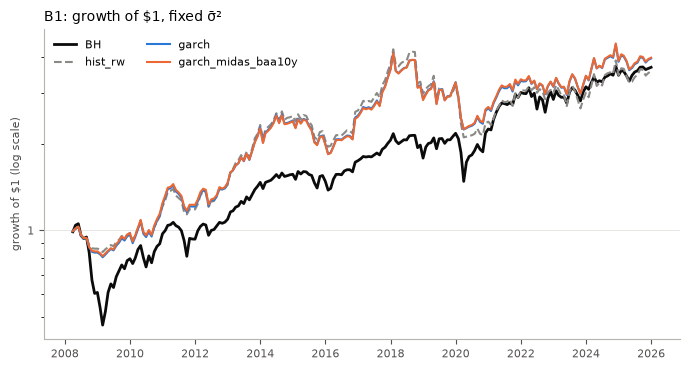

In [46]:
show_block("B1")

## A.3 B2: Macro information in a linear model

**Question: Do macro variables plus VIX help a linear model that uses only past volatility?**

| Pair | a | b | Isolates |
|---|---|---|---|
| B2.1 | `en_full_macro` | `en_no_macro` | total effect of macro + VIX |

B2 Macro information in a linear model: Do macro variables plus VIX help over the historical HAR benchmark?

Bucket portfolios against the benchmarks (fixed σ̄²; last two columns: expanding):


,SR,ΔSR vs BH,p vs BH,α % p.a.,α t,ΔSR vs hist_rw,p vs hist_rw,MaxDD %,turnover,% capped,SR (expanding),p vs BH (expanding)
portfolio,,,,,,,,,,,,
BH,0.476,NaN,NaN,NaN,NaN,NaN,NaN,-55.519,0.000,NaN,0.476,NaN
hist_rw,0.468,-0.008,0.969,2.175,0.644,NaN,NaN,-50.558,0.493,21.308,0.603,0.520
en_full_macro,0.399,-0.077,0.691,0.613,0.194,-0.069,0.230,-52.151,0.338,3.271,0.539,0.725



Pair tests, SR(a) = SR(b):


,a,b,isolates,SR_a,SR_b,ΔSR,LW t,p,sig,result,ΔSR (expanding),p (expanding),result (expanding),same sign
pair,,,,,,,,,,,,,,
B2.1,en_full_macro,en_no_macro,total effect of macro + VIX,0.399,0.454,-0.055,-1.364,0.179,,n.s.,-0.054,0.120,n.s.,True


B2.1: no significant difference between en_full_macro and en_no_macro (ΔSR -0.055, p = 0.179)   [expanding: ΔSR -0.054, p = 0.120]


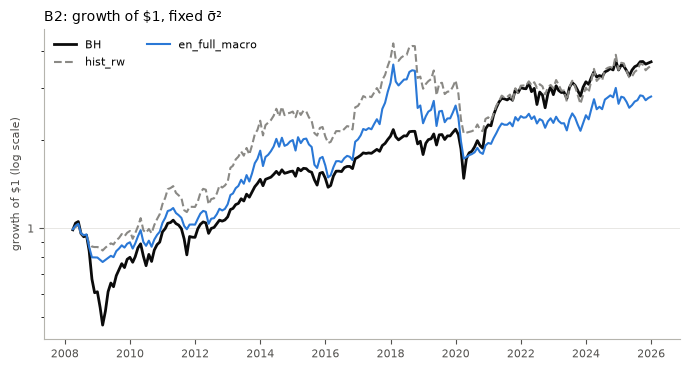

In [47]:
show_block("B2")

## A.4 B3: Effect of VIX, Elastic Net

**Question: Is VIX doing all the work, or do the other macro variables add information?**

| Pair | a | b | Isolates |
|---|---|---|---|
| B3.1 | `en_full_macro` | `en_no_vix` | VIX on top of the other macro variables |
| B3.2 | `en_vix_only` | `en_no_macro` | VIX on its own |
| B3.3 | `en_full_macro` | `en_vix_only` | other macro variables on top of VIX |

**How to read B3 and B4** (the 2×2 of VIX × other macro variables):

| Pattern | Conclusion |
|---|---|
| VIX-only beats no-macro, and full ≈ VIX-only | VIX is doing all the work |
| Full beats VIX-only | The other macro variables add information beyond VIX |
| Full beats no-VIX | VIX adds information beyond the other macro variables |
| All ≈ 0 | Neither helps the portfolio |

B3 Effect of VIX, Elastic Net: Is VIX doing all the work, or do the other macro variables add information?

Bucket portfolios against the benchmarks (fixed σ̄²; last two columns: expanding):


,SR,ΔSR vs BH,p vs BH,α % p.a.,α t,ΔSR vs hist_rw,p vs hist_rw,MaxDD %,turnover,% capped,SR (expanding),p vs BH (expanding)
portfolio,,,,,,,,,,,,
BH,0.476,NaN,NaN,NaN,NaN,NaN,NaN,-55.519,0.000,NaN,0.476,NaN
hist_rw,0.468,-0.008,0.969,2.175,0.644,NaN,NaN,-50.558,0.493,21.308,0.603,0.520
en_no_macro,0.454,-0.022,0.914,1.625,0.505,-0.014,0.675,-52.705,0.499,5.327,0.593,0.532
en_no_vix,0.416,-0.060,0.764,0.787,0.242,-0.052,0.389,-55.741,0.369,4.766,0.550,0.679
en_vix_only,0.451,-0.025,0.895,1.586,0.495,-0.017,0.685,-50.419,0.390,2.991,0.559,0.667
en_full_macro,0.399,-0.077,0.691,0.613,0.194,-0.069,0.230,-52.151,0.338,3.271,0.539,0.725



Pair tests, SR(a) = SR(b):


,a,b,isolates,SR_a,SR_b,ΔSR,LW t,p,sig,result,ΔSR (expanding),p (expanding),result (expanding),same sign
pair,,,,,,,,,,,,,,
B3.1,en_full_macro,en_no_vix,VIX on top of the other macro variables,0.399,0.416,-0.017,-0.407,0.703,,n.s.,-0.011,0.811,n.s.,True
B3.2,en_vix_only,en_no_macro,VIX on its own,0.451,0.454,-0.003,-0.102,0.917,,n.s.,-0.034,0.237,n.s.,True
B3.3,en_full_macro,en_vix_only,other macro variables on top of VIX,0.399,0.451,-0.052,-1.699,0.104,,n.s.,-0.020,0.470,n.s.,True


B3.1: no significant difference between en_full_macro and en_no_vix (ΔSR -0.017, p = 0.703)   [expanding: ΔSR -0.011, p = 0.811]
B3.2: no significant difference between en_vix_only and en_no_macro (ΔSR -0.003, p = 0.917)   [expanding: ΔSR -0.034, p = 0.237]
B3.3: no significant difference between en_full_macro and en_vix_only (ΔSR -0.052, p = 0.104)   [expanding: ΔSR -0.020, p = 0.470]


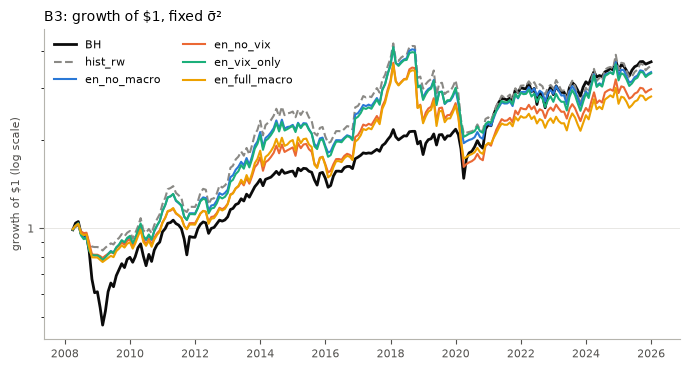

In [48]:
show_block("B3")

## A.5 B4: Effect of VIX, XGBoost (robustness check for B3)

**Question: Do the B3 findings hold with a non-linear model?**

| Pair | a | b | Isolates |
|---|---|---|---|
| B4.0 | `xgb_full_macro` | `xgb_no_macro` | total effect of macro + VIX |
| B4.1 | `xgb_full_macro` | `xgb_no_vix` | VIX on top of the other macro variables |
| B4.2 | `xgb_vix_only` | `xgb_no_macro` | VIX on its own |
| B4.3 | `xgb_full_macro` | `xgb_vix_only` | other macro variables on top of VIX |

**How to read B3 and B4** (the 2×2 of VIX × other macro variables):

| Pattern | Conclusion |
|---|---|
| VIX-only beats no-macro, and full ≈ VIX-only | VIX is doing all the work |
| Full beats VIX-only | The other macro variables add information beyond VIX |
| Full beats no-VIX | VIX adds information beyond the other macro variables |
| All ≈ 0 | Neither helps the portfolio |

B4 Effect of VIX, XGBoost (robustness check for B3): Do the B3 findings hold with a non-linear model?

Bucket portfolios against the benchmarks (fixed σ̄²; last two columns: expanding):


,SR,ΔSR vs BH,p vs BH,α % p.a.,α t,ΔSR vs hist_rw,p vs hist_rw,MaxDD %,turnover,% capped,SR (expanding),p vs BH (expanding)
portfolio,,,,,,,,,,,,
BH,0.476,NaN,NaN,NaN,NaN,NaN,NaN,-55.519,0.000,NaN,0.476,NaN
hist_rw,0.468,-0.008,0.969,2.175,0.644,NaN,NaN,-50.558,0.493,21.308,0.603,0.520
xgb_no_macro,0.361,-0.115,0.511,-0.715,-0.245,-0.107,0.117,-55.092,0.311,1.028,0.510,0.839
xgb_no_vix,0.329,-0.147,0.373,-1.368,-0.490,-0.139,0.130,-55.633,0.268,0.467,0.484,0.962
xgb_vix_only,0.351,-0.125,0.487,-0.568,-0.190,-0.117,0.098,-52.781,0.329,1.028,0.463,0.944
xgb_full_macro,0.310,-0.166,0.324,-1.493,-0.528,-0.158,0.074,-54.700,0.293,1.402,0.454,0.889



Pair tests, SR(a) = SR(b):


,a,b,isolates,SR_a,SR_b,ΔSR,LW t,p,sig,result,ΔSR (expanding),p (expanding),result (expanding),same sign
pair,,,,,,,,,,,,,,
B4.0,xgb_full_macro,xgb_no_macro,total effect of macro + VIX,0.310,0.361,-0.051,-1.108,0.293,,n.s.,-0.056,0.091,a worse,True
B4.1,xgb_full_macro,xgb_no_vix,VIX on top of the other macro variables,0.310,0.329,-0.019,-0.453,0.668,,n.s.,-0.030,0.338,n.s.,True
B4.2,xgb_vix_only,xgb_no_macro,VIX on its own,0.351,0.361,-0.010,-0.197,0.849,,n.s.,-0.047,0.216,n.s.,True
B4.3,xgb_full_macro,xgb_vix_only,other macro variables on top of VIX,0.310,0.351,-0.041,-1.362,0.197,,n.s.,-0.009,0.725,n.s.,True


B4.0: no significant difference between xgb_full_macro and xgb_no_macro (ΔSR -0.051, p = 0.293)   [expanding: ΔSR -0.056, p = 0.091]
B4.1: no significant difference between xgb_full_macro and xgb_no_vix (ΔSR -0.019, p = 0.668)   [expanding: ΔSR -0.030, p = 0.338]
B4.2: no significant difference between xgb_vix_only and xgb_no_macro (ΔSR -0.010, p = 0.849)   [expanding: ΔSR -0.047, p = 0.216]
B4.3: no significant difference between xgb_full_macro and xgb_vix_only (ΔSR -0.041, p = 0.197)   [expanding: ΔSR -0.009, p = 0.725]


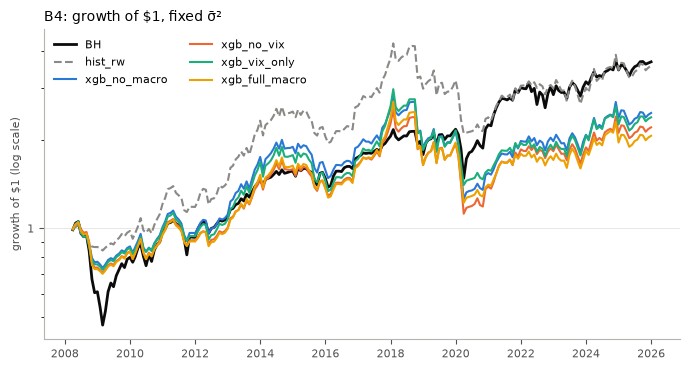

In [49]:
show_block("B4")

## A.6 B5: Non-linearity

**Question: With the same information, does XGBoost beat Elastic Net?**

| Pair | a | b | Isolates |
|---|---|---|---|
| B5.1 | `xgb_no_macro` | `en_no_macro` | no macro |
| B5.2 | `xgb_no_vix` | `en_no_vix` | macro without VIX |
| B5.3 | `xgb_vix_only` | `en_vix_only` | VIX only |
| B5.4 | `xgb_full_macro` | `en_full_macro` | full macro + VIX |

B5 Non-linearity: With the same information, does XGBoost beat Elastic Net?

Bucket portfolios against the benchmarks (fixed σ̄²; last two columns: expanding):


,SR,ΔSR vs BH,p vs BH,α % p.a.,α t,ΔSR vs hist_rw,p vs hist_rw,MaxDD %,turnover,% capped,SR (expanding),p vs BH (expanding)
portfolio,,,,,,,,,,,,
BH,0.476,NaN,NaN,NaN,NaN,NaN,NaN,-55.519,0.000,NaN,0.476,NaN
hist_rw,0.468,-0.008,0.969,2.175,0.644,NaN,NaN,-50.558,0.493,21.308,0.603,0.520
en_no_macro,0.454,-0.022,0.914,1.625,0.505,-0.014,0.675,-52.705,0.499,5.327,0.593,0.532
xgb_no_macro,0.361,-0.115,0.511,-0.715,-0.245,-0.107,0.117,-55.092,0.311,1.028,0.510,0.839
en_no_vix,0.416,-0.060,0.764,0.787,0.242,-0.052,0.389,-55.741,0.369,4.766,0.550,0.679
xgb_no_vix,0.329,-0.147,0.373,-1.368,-0.490,-0.139,0.130,-55.633,0.268,0.467,0.484,0.962
en_vix_only,0.451,-0.025,0.895,1.586,0.495,-0.017,0.685,-50.419,0.390,2.991,0.559,0.667
xgb_vix_only,0.351,-0.125,0.487,-0.568,-0.190,-0.117,0.098,-52.781,0.329,1.028,0.463,0.944
en_full_macro,0.399,-0.077,0.691,0.613,0.194,-0.069,0.230,-52.151,0.338,3.271,0.539,0.725



Pair tests, SR(a) = SR(b):


,a,b,isolates,SR_a,SR_b,ΔSR,LW t,p,sig,result,ΔSR (expanding),p (expanding),result (expanding),same sign
pair,,,,,,,,,,,,,,
B5.1,xgb_no_macro,en_no_macro,no macro,0.361,0.454,-0.093,-1.681,0.130,,n.s.,-0.083,0.053,a worse,True
B5.2,xgb_no_vix,en_no_vix,macro without VIX,0.329,0.416,-0.087,-1.594,0.145,,n.s.,-0.066,0.141,n.s.,True
B5.3,xgb_vix_only,en_vix_only,VIX only,0.351,0.451,-0.100,-2.322,0.034,**,a worse,-0.096,0.028,a worse,True
B5.4,xgb_full_macro,en_full_macro,full macro + VIX,0.310,0.399,-0.089,-1.917,0.077,*,a worse,-0.086,0.051,a worse,True


B5.1: no significant difference between xgb_no_macro and en_no_macro (ΔSR -0.093, p = 0.130)   [expanding: ΔSR -0.083, p = 0.053]
B5.2: no significant difference between xgb_no_vix and en_no_vix (ΔSR -0.087, p = 0.145)   [expanding: ΔSR -0.066, p = 0.141]
B5.3: xgb_vix_only gives a significantly worse portfolio than en_vix_only (ΔSR -0.100, p = 0.034)   [expanding: ΔSR -0.096, p = 0.028]
B5.4: xgb_full_macro gives a weakly significantly worse portfolio than en_full_macro (ΔSR -0.089, p = 0.077)   [expanding: ΔSR -0.086, p = 0.051]


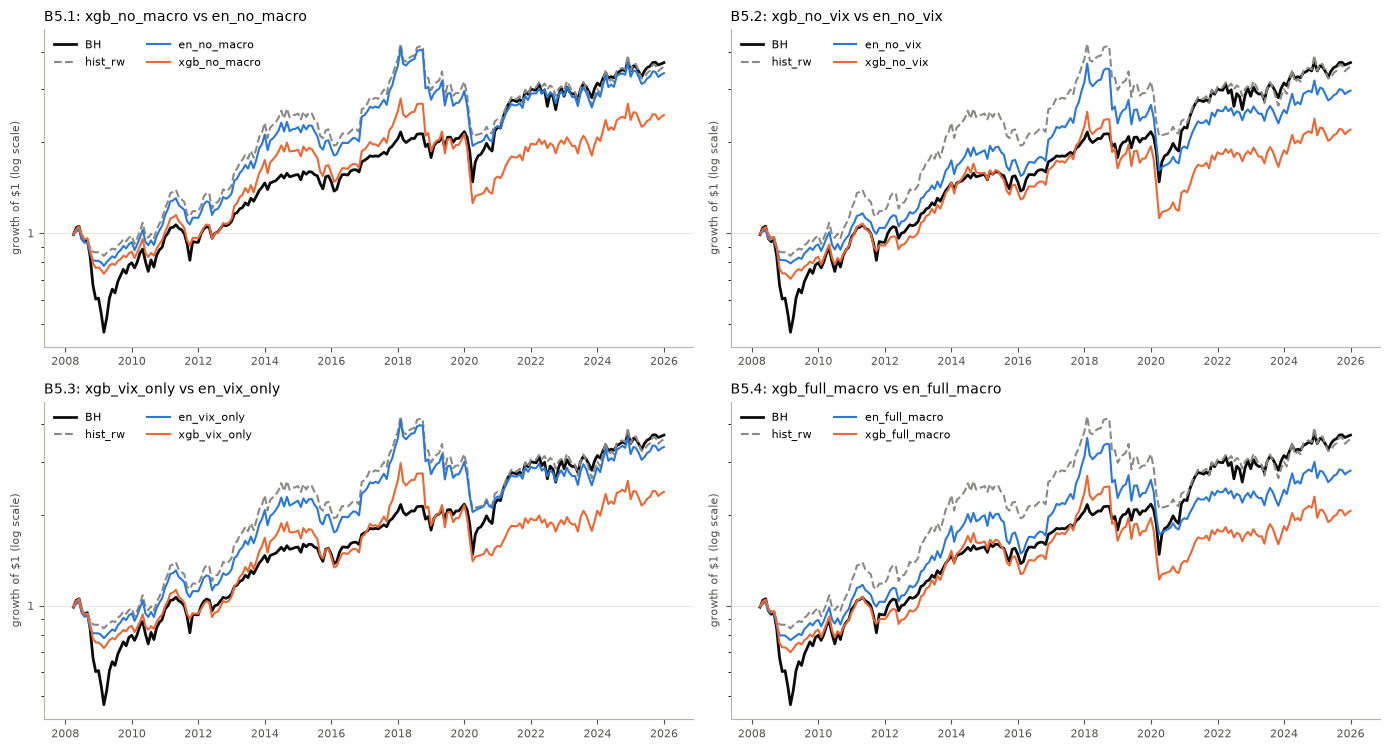

In [50]:
show_block("B5")

## A.7 Bucket scoreboard

Every pair in one table: the answer to each sub-question on the portfolio side. `result` is
"a better" or "a worse" when the Ledoit-Wolf p-value is below 0.10, and "n.s." otherwise.
`same sign` checks the direction of ΔSR under the expanding σ̄².

In [51]:
scoreboard = pair_rows()
scoreboard.insert(1, "question", [BLOCKS[b]["title"] for b in scoreboard["block"]])
scoreboard

,block,question,a,b,isolates,SR_a,SR_b,ΔSR,LW t,p,sig,result,ΔSR (expanding),p (expanding),result (expanding),same sign
pair,,,,,,,,,,,,,,,,
B0.1,B0,Volatility-timing baseline,garch,hist_rw,fitted GARCH vs naive history,0.497,0.468,0.029,0.736,0.469,,n.s.,0.005,0.894,n.s.,True
B1.1,B1,GARCH family,garch_midas_baa10y,garch,credit spread (BAA10Y) as the long-run component,0.499,0.497,0.002,0.301,0.774,,n.s.,0.002,0.782,n.s.,True
B2.1,B2,Macro information in a linear model,en_full_macro,en_no_macro,total effect of macro + VIX,0.399,0.454,-0.055,-1.364,0.179,,n.s.,-0.054,0.120,n.s.,True
B3.1,B3,"Effect of VIX, Elastic Net",en_full_macro,en_no_vix,VIX on top of the other macro variables,0.399,0.416,-0.017,-0.407,0.703,,n.s.,-0.011,0.811,n.s.,True
B3.2,B3,"Effect of VIX, Elastic Net",en_vix_only,en_no_macro,VIX on its own,0.451,0.454,-0.003,-0.102,0.917,,n.s.,-0.034,0.237,n.s.,True
B3.3,B3,"Effect of VIX, Elastic Net",en_full_macro,en_vix_only,other macro variables on top of VIX,0.399,0.451,-0.052,-1.699,0.104,,n.s.,-0.020,0.470,n.s.,True
B4.0,B4,"Effect of VIX, XGBoost (robustness check for B3)",xgb_full_macro,xgb_no_macro,total effect of macro + VIX,0.310,0.361,-0.051,-1.108,0.293,,n.s.,-0.056,0.091,a worse,True
B4.1,B4,"Effect of VIX, XGBoost (robustness check for B3)",xgb_full_macro,xgb_no_vix,VIX on top of the other macro variables,0.310,0.329,-0.019,-0.453,0.668,,n.s.,-0.030,0.338,n.s.,True
B4.2,B4,"Effect of VIX, XGBoost (robustness check for B3)",xgb_vix_only,xgb_no_macro,VIX on its own,0.351,0.361,-0.010,-0.197,0.849,,n.s.,-0.047,0.216,n.s.,True


# Part B: Per-ETF portfolios

Each ETF's managed series positionᵢ,ₜ₊₁ is rescaled by cᵢ = σ(rᵢ − rf) / σ(positionᵢ) to the
volatility of that ETF's own buy-and-hold, so every comparison is at matched risk. cᵢ does not
change the Sharpe ratio or the Ledoit-Wolf test. The `Cyclical` column repeats the bucket result
for reference. The heatmaps show the main (fixed) specification; the full tables for both are in
B.3.

## B.1 Against buy-and-hold and against `hist_rw`

ΔSR of each model's managed ETF against that ETF's buy-and-hold (left) and against the `hist_rw`
portfolio for the same ETF (right). Blue: the model is better.

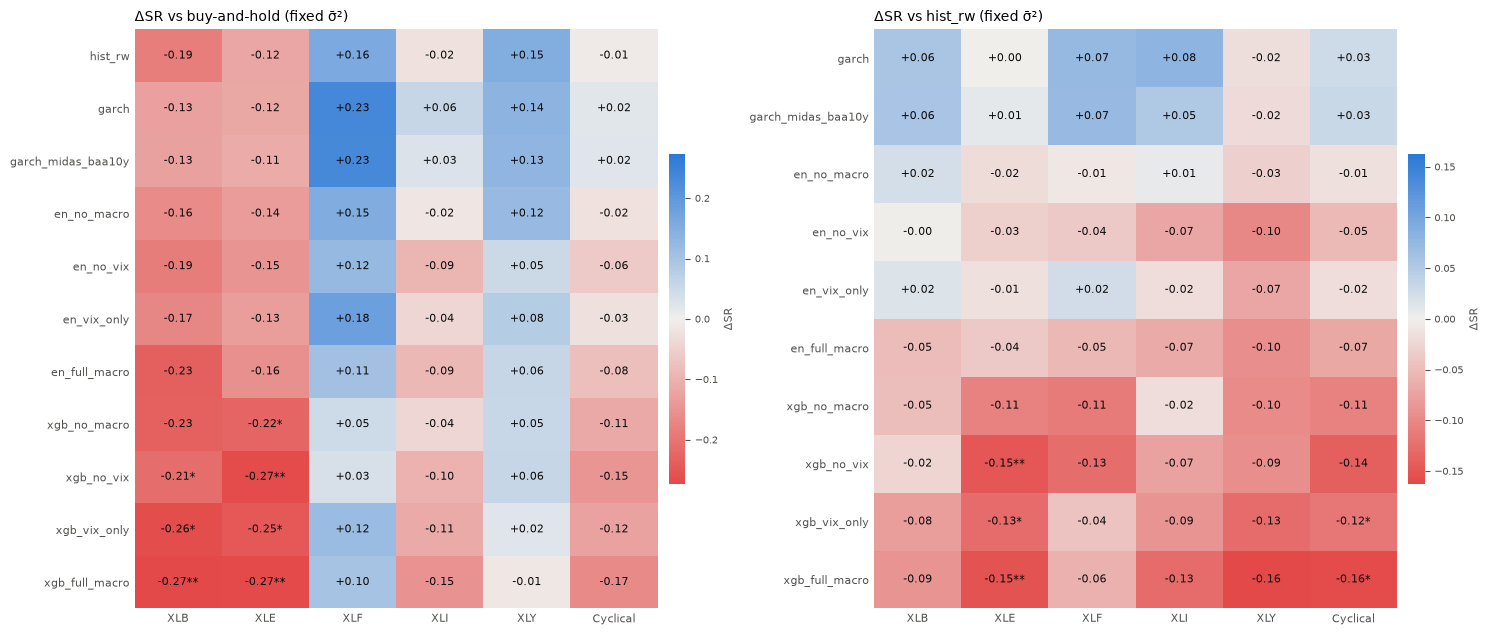

In [52]:
units = TICKERS + ["Cyclical"]
etf_main = vs_bh_etf[MAIN_SPEC]
d_bh = etf_main["SR_diff"].unstack("ETF").loc[MODELS, TICKERS]
p_bh = etf_main["LW_p"].unstack("ETF").loc[MODELS, TICKERS]
d_bh["Cyclical"] = vs_bh[MAIN_SPEC].loc[MODELS, "SR_diff_vs_BH"]
p_bh["Cyclical"] = vs_bh[MAIN_SPEC].loc[MODELS, "LW_p"]

others = [m for m in MODELS if m != BENCHMARK]
vs_rw = lw.loc[MAIN_SPEC].xs(BENCHMARK, level="b").loc[others]
d_rw = vs_rw["SR_diff"].unstack("ETF").loc[others, units]
p_rw = vs_rw["LW_p"].unstack("ETF").loc[others, units]

fig, axes = plt.subplots(1, 2, figsize=(15, 0.45 * len(MODELS) + 1.5))
heatmap(d_bh, p_bh, axes[0], f"ΔSR vs buy-and-hold ({MAIN_SPEC} σ̄²)")
heatmap(d_rw, p_rw, axes[1], f"ΔSR vs {BENCHMARK} ({MAIN_SPEC} σ̄²)")
fig.tight_layout()
plt.show()

## B.2 Block pairs per ETF

ΔSR = SR(a) − SR(b) for every block pair and ETF. Blue: the richer model a gives the better
portfolio. The rows are grouped by block.

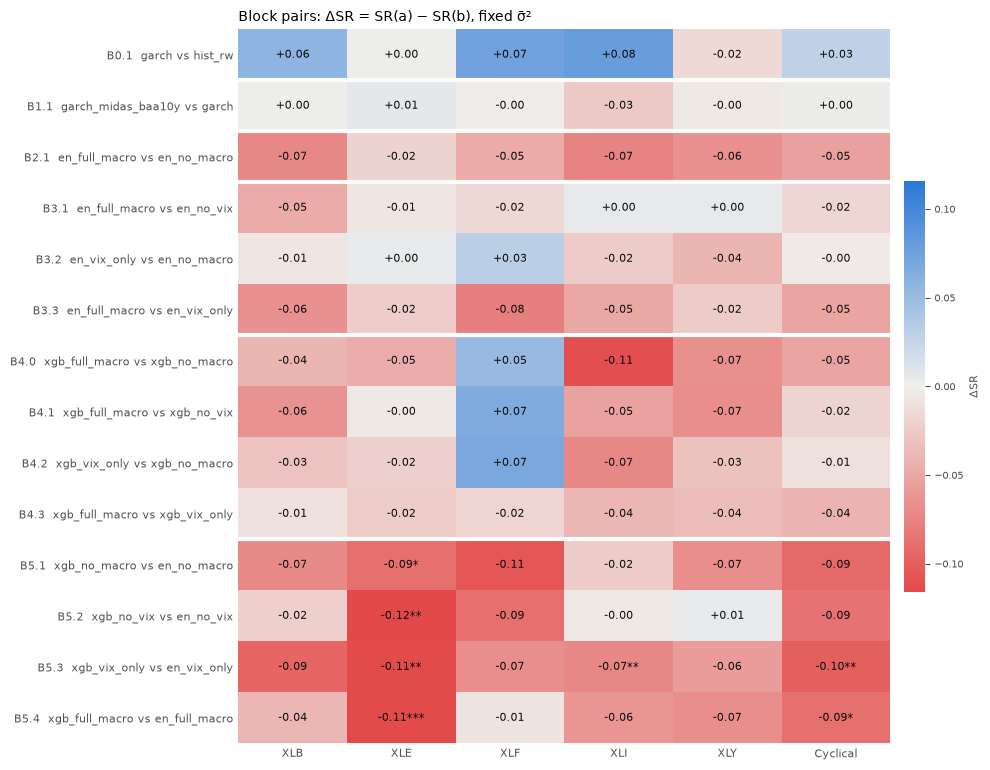

In [53]:
pair_etf = {}
for spec in SPECS:
    sub = lw.loc[spec]
    idx = [(p.a, p.b) for _, p in pairs.iterrows()]
    labels = [f"{pid}  {p.a} vs {p.b}" for pid, p in pairs.iterrows()]
    pair_etf[spec] = {
        "SR_diff": pd.DataFrame([sub.loc[i, "SR_diff"][units].values for i in idx], index=labels, columns=units),
        "LW_p": pd.DataFrame([sub.loc[i, "LW_p"][units].values for i in idx], index=labels, columns=units),
    }

fig, ax = plt.subplots(figsize=(10, 0.45 * len(pairs) + 1.5))
heatmap(pair_etf[MAIN_SPEC]["SR_diff"], pair_etf[MAIN_SPEC]["LW_p"], ax,
        f"Block pairs: ΔSR = SR(a) − SR(b), {MAIN_SPEC} σ̄²")
breaks = np.flatnonzero(pairs["block"].to_numpy()[1:] != pairs["block"].to_numpy()[:-1])
for y in breaks:
    ax.axhline(y + 0.5, color="#fcfcfb", linewidth=3)
fig.tight_layout()
plt.show()

## B.3 Full per-ETF tables

Every model against its own ETF's buy-and-hold, under each specification (`LW_t`, `LW_p`: the
Ledoit-Wolf test; `alpha_*`: the alpha on that ETF's BH).

In [54]:
for spec in SPECS:
    print(f"--- {spec} σ̄² ---")
    display(vs_bh_etf[spec])

--- fixed σ̄² ---


c_i  SR_managed  SR_BH  SR_diff   LW_t  LW_p  alpha_annual  alpha_t  maxDD_managed  maxDD_BH  avg_turnover  pct_capped
model              ETF                                                                                                                         
hist_rw            XLB 1.010       0.176  0.361   -0.185 -1.063 0.347        -0.022   -0.656         -0.476    -0.559         0.421      23.832
                   XLE 1.033       0.119  0.237   -0.118 -0.801 0.437        -0.017   -0.435         -0.838    -0.660         0.359      24.766
                   XLF 1.141       0.522  0.363    0.159  0.667 0.561         0.061    1.342         -0.456    -0.708         0.508      28.037
                   XLI 1.266       0.527  0.550   -0.023 -0.120 0.911         0.023    0.675         -0.434    -0.555         0.586       9.813
                   XLY 1.209       0.822  0.671    0.151  0.739 0.483         0.069    1.956         -0.382    -0.454         0.516      20.093
garch              XLB 1.198       0.233  0.361   -0.129 -0.829 0.466        -0.013   -0.434         -0.429    -0.559         0.333       4.206
                   XLE 1.100       0.120  0.237   -0.117 -0.847 0.414        -0.018   -0.489         -0.833    -0.660         0.321       9.813
                   XLF 1.391       0.596  0.363    0.233  1.047 0.397         0.075    1.764         -0.336    -0.708         0.494       5.607
                   XLI 1.655       0.606  0.550    0.056  0.340 0.762         0.031    1.040         -0.327    -0.555         0.401       0.000
                   XLY 1.437       0.807  0.671    0.136  0.761 0.488         0.060    1.867         -0.310    -0.454         0.456       2.336
garch_midas_baa10y XLB 1.197       0.234  0.361   -0.127 -0.794 0.486        -0.012   -0.407         -0.432    -0.559         0.325       4.206
                   XLE 1.116       0.127  0.237   -0.110 -0.791 0.444        -0.017   -0.447         -0.822    -0.660         0.320       9.346
                   XLF 1.370       0.594  0.363    0.231  1.049 0.392         0.075    1.775         -0.342    -0.708         0.495       5.607
                   XLI 1.604       0.580  0.550    0.030  0.177 0.866         0.026    0.864         -0.360    -0.555         0.371       0.000
                   XLY 1.413       0.803  0.671    0.131  0.730 0.505         0.060    1.834         -0.320    -0.454         0.450       2.336
en_no_macro        XLB 1.262       0.199  0.361   -0.163 -1.031 0.354        -0.020   -0.646         -0.522    -0.559         0.430       8.411
                   XLE 1.217       0.101  0.237   -0.136 -1.009 0.323        -0.024   -0.660         -0.845    -0.660         0.385       7.477
                   XLF 1.522       0.516  0.363    0.153  0.661 0.565         0.060    1.341         -0.450    -0.708         0.603       4.206
                   XLI 1.673       0.534  0.550   -0.016 -0.093 0.928         0.019    0.590         -0.437    -0.555         0.511       1.402
                   XLY 1.443       0.792  0.671    0.121  0.620 0.559         0.059    1.731         -0.400    -0.454         0.514       5.140
en_no_vix          XLB 1.245       0.174  0.361   -0.188 -1.154 0.300        -0.025   -0.802         -0.545    -0.559         0.328       8.879
                   XLE 1.386       0.088  0.237   -0.149 -1.241 0.231        -0.030   -0.890         -0.841    -0.660         0.332       3.738
                   XLF 1.458       0.485  0.363    0.122  0.512 0.649         0.052    1.124         -0.513    -0.708         0.421       5.140
                   XLI 1.579       0.456  0.550   -0.094 -0.515 0.644         0.003    0.103         -0.523    -0.555         0.322       0.935
                   XLY 1.425       0.722  0.671    0.051  0.264 0.795         0.046    1.366         -0.418    -0.454         0.389       5.140
en_vix_only        XLB 1.299       0.192  0.361   -0.169 -1.060 0.347        -0.021   -0.691         -0.493    -0.559         0.326      

--- expanding σ̄² ---


c_i  SR_managed  SR_BH  SR_diff   LW_t  LW_p  alpha_annual  alpha_t  maxDD_managed  maxDD_BH  avg_turnover  pct_capped
model              ETF                                                                                                                         
hist_rw            XLB 0.788       0.315  0.361   -0.046 -0.288 0.797         0.003    0.095         -0.390    -0.559         0.242      54.206
                   XLE 0.816       0.221  0.237   -0.015 -0.119 0.917         0.006    0.188         -0.787    -0.660         0.219      50.000
                   XLF 0.728       0.627  0.363    0.264  1.268 0.342         0.075    1.772         -0.341    -0.708         0.127      72.430
                   XLI 0.832       0.630  0.550    0.080  0.487 0.667         0.034    1.125         -0.380    -0.555         0.287      47.196
                   XLY 0.868       0.914  0.671    0.243  1.407 0.211         0.077    2.474         -0.258    -0.454         0.264      46.262
garch              XLB 0.819       0.301  0.361   -0.060 -0.400 0.720        -0.001   -0.047         -0.364    -0.559         0.226      38.318
                   XLE 0.816       0.226  0.237   -0.011 -0.090 0.937         0.007    0.214         -0.769    -0.660         0.187      43.925
                   XLF 0.738       0.632  0.363    0.270  1.341 0.322         0.076    1.885         -0.342    -0.708         0.117      71.495
                   XLI 0.868       0.657  0.550    0.108  0.649 0.563         0.039    1.264         -0.295    -0.555         0.257      35.981
                   XLY 0.897       0.905  0.671    0.234  1.441 0.203         0.073    2.457         -0.234    -0.454         0.265      37.850
garch_midas_baa10y XLB 0.821       0.313  0.361   -0.049 -0.317 0.777         0.001    0.030         -0.366    -0.559         0.227      36.916
                   XLE 0.820       0.217  0.237   -0.019 -0.160 0.890         0.004    0.137         -0.769    -0.660         0.191      42.056
                   XLF 0.735       0.628  0.363    0.266  1.343 0.318         0.075    1.892         -0.346    -0.708         0.117      71.028
                   XLI 0.849       0.658  0.550    0.108  0.652 0.563         0.038    1.248         -0.299    -0.555         0.252      34.112
                   XLY 0.888       0.911  0.671    0.240  1.471 0.198         0.074    2.473         -0.246    -0.454         0.265      37.383
en_no_macro        XLB 0.875       0.283  0.361   -0.079 -0.532 0.629        -0.006   -0.195         -0.422    -0.559         0.304      29.907
                   XLE 0.875       0.202  0.237   -0.035 -0.289 0.788        -0.000   -0.007         -0.801    -0.660         0.252      31.776
                   XLF 0.784       0.638  0.363    0.276  1.319 0.321         0.078    1.860         -0.340    -0.708         0.174      62.150
                   XLI 0.925       0.646  0.550    0.096  0.613 0.578         0.035    1.215         -0.369    -0.555         0.353      28.037
                   XLY 0.948       0.907  0.671    0.236  1.416 0.207         0.073    2.414         -0.299    -0.454         0.308      31.776
en_no_vix          XLB 0.867       0.266  0.361   -0.095 -0.630 0.571        -0.009   -0.316         -0.442    -0.559         0.237      28.037
                   XLE 0.951       0.179  0.237   -0.057 -0.523 0.614        -0.007   -0.247         -0.813    -0.660         0.257      16.355
                   XLF 0.735       0.589  0.363    0.227  1.032 0.405         0.068    1.539         -0.428    -0.708         0.124      65.421
                   XLI 0.880       0.567  0.550    0.017  0.104 0.925         0.020    0.623         -0.429    -0.555         0.235      24.299
                   XLY 0.930       0.849  0.671    0.178  1.069 0.332         0.062    2.085         -0.289    -0.454         0.255      32.243
en_vix_only        XLB 0.871       0.271  0.361   -0.091 -0.591 0.600        -0.007   -0.250         -0.410    -0.559         0.234      

# Part C: Robustness, expanding reference σ̄²ᵢ,ₜ

**Why the main results use a fixed reference.** With a constant reference σ̄²ᵢ, the only thing
moving the weights from month to month is the forecast σ̂²ᵢ,ₜ₊₁. Comparing managed portfolios
across models is then a direct test of forecast skill, which is the research question. With an
expanding reference, σ̄²ᵢ,ₜ moves too, and the weights pick up a re-levering effect that has
nothing to do with the forecast. The Phase 2 proposal (Section 3) defines the reference as "the
ETF's average training-window variance"; the models' training window expands, so that wording also
admits the expanding mean, reported here as the alternative specification.

**What the expanding reference does and does not affect.** Within a pair, both models share the
same σ̄²ᵢ,ₜ, so the re-levering affects a and b alike and the pair tests remain tests of forecast
skill. The comparisons with buy-and-hold are where the specification matters.

## C.1 Do the pair results hold?

For each pair: the result under each specification, and the share of the five ETFs whose ΔSR has
the same sign under both.

In [55]:
etf_sign_agree = pd.Series({
    lbl: (np.sign(pair_etf[MAIN_SPEC]["SR_diff"].loc[lbl, TICKERS])
          == np.sign(pair_etf[ROBUST_SPEC]["SR_diff"].loc[lbl, TICKERS])).mean()
    for lbl in pair_etf[MAIN_SPEC]["SR_diff"].index})
robust = scoreboard[["block", "a", "b", "ΔSR", "p", "result", f"ΔSR ({ROBUST_SPEC})",
                     f"p ({ROBUST_SPEC})", f"result ({ROBUST_SPEC})", "same sign"]].copy()
robust["same result"] = robust["result"] == robust[f"result ({ROBUST_SPEC})"]
robust["ETFs same sign"] = etf_sign_agree.to_numpy()
robust

,block,a,b,ΔSR,p,result,ΔSR (expanding),p (expanding),result (expanding),same sign,same result,ETFs same sign
pair,,,,,,,,,,,,
B0.1,B0,garch,hist_rw,0.029,0.469,n.s.,0.005,0.894,n.s.,True,True,0.800
B1.1,B1,garch_midas_baa10y,garch,0.002,0.774,n.s.,0.002,0.782,n.s.,True,True,0.400
B2.1,B2,en_full_macro,en_no_macro,-0.055,0.179,n.s.,-0.054,0.120,n.s.,True,True,1.000
B3.1,B3,en_full_macro,en_no_vix,-0.017,0.703,n.s.,-0.011,0.811,n.s.,True,True,0.800
B3.2,B3,en_vix_only,en_no_macro,-0.003,0.917,n.s.,-0.034,0.237,n.s.,True,True,0.600
B3.3,B3,en_full_macro,en_vix_only,-0.052,0.104,n.s.,-0.020,0.470,n.s.,True,True,1.000
B4.0,B4,xgb_full_macro,xgb_no_macro,-0.051,0.293,n.s.,-0.056,0.091,a worse,True,False,0.800
B4.1,B4,xgb_full_macro,xgb_no_vix,-0.019,0.668,n.s.,-0.030,0.338,n.s.,True,True,0.600
B4.2,B4,xgb_vix_only,xgb_no_macro,-0.010,0.849,n.s.,-0.047,0.216,n.s.,True,True,0.800


## C.2 Timing or re-levering?

Under the expanding reference, a managed portfolio's performance mixes two things: the re-levering
that comes from σ̄²ᵢ,ₜ rising after crises, and the timing that comes from the forecast. The
**control** captures only the first. It uses the same weight formula and cap, with the fixed
2003-03 to 2008-02 reference in place of σ̂²:

w^ctrl_{i,t} = min(σ̄²ᵢ,ₜ / σ̄²ᵢ,fixed, 2).

It starts at 1 and rises only when the expanding mean rises. One regression per model, with
Newey-West standard errors:

f^σ_t = α + β_BH · BH_t + β_ctrl · control_t + εₜ.

**α is what the forecast adds beyond holding the ETFs and beyond re-levering.** For the control
row, α and β_BH come from a regression on BH alone; its fixed-specification entries are empty,
since under the fixed reference the control is identically buy-and-hold.

**% capped** under each specification shows how much of the expanding version is leverage: a
model at the cap far more often under the expanding reference is mostly being re-levered, not
timed.

In [56]:
exp_res = portfolios["expanding"]
control = exp_res[CONTROL]

rows = {}
for m in MODELS:
    rows[m] = {
        "SR_fixed": vs_bh["fixed"].at[m, "ann_sharpe"],
        "SR_expanding": vs_bh["expanding"].at[m, "ann_sharpe"],
        **alpha_vs_bh_and_control(exp_res[m], bh, control),
        "pct_capped_fixed": pct_capped_pooled(portfolios["fixed"][m]["weights_base"], K_CAP),
        "pct_capped_expanding": pct_capped_pooled(exp_res[m]["weights_base"], K_CAP),
    }

al = alpha_regression(control["managed"], bh.to_frame("BH"))
rows[CONTROL] = {
    "SR_fixed": np.nan,
    "SR_expanding": performance_row(control["managed"], control["bucket_weights"])["ann_sharpe"],
    "alpha_annual": al["alpha_annual"], "alpha_t": al["alpha_t"], "alpha_p": al["alpha_p"],
    "beta_BH": al["beta_BH"], "beta_control": np.nan, "R2": al["R2"],
    "pct_capped_fixed": np.nan,
    "pct_capped_expanding": pct_capped_pooled(control["weights_base"], K_CAP),
}

extension = pd.DataFrame(rows).T.rename_axis("portfolio")
extension = extension[["SR_fixed", "SR_expanding", "alpha_annual", "alpha_t", "alpha_p",
                       "beta_BH", "beta_control", "R2", "pct_capped_fixed", "pct_capped_expanding"]]
extension

,SR_fixed,SR_expanding,alpha_annual,alpha_t,alpha_p,beta_BH,beta_control,R2,pct_capped_fixed,pct_capped_expanding
portfolio,,,,,,,,,,
hist_rw,0.468,0.603,0.029,1.016,0.310,0.082,0.751,0.694,21.308,54.019
garch,0.497,0.608,0.027,1.018,0.309,-0.054,0.894,0.707,4.393,45.514
garch_midas_baa10y,0.499,0.610,0.027,1.020,0.308,-0.071,0.915,0.713,4.299,44.299
en_no_macro,0.454,0.593,0.028,1.018,0.309,0.257,0.588,0.713,5.327,36.729
en_no_vix,0.416,0.550,0.025,0.884,0.377,0.653,0.196,0.720,4.766,33.271
en_vix_only,0.451,0.559,0.022,0.778,0.437,0.156,0.674,0.686,2.991,38.411
en_full_macro,0.399,0.539,0.023,0.831,0.406,0.491,0.336,0.682,3.271,36.075
xgb_no_macro,0.361,0.510,0.015,0.602,0.547,0.688,0.186,0.762,1.028,33.271
xgb_no_vix,0.329,0.484,0.014,0.564,0.573,0.946,-0.074,0.761,0.467,29.533


## Save the tables

Written to `results/eval/`:

- `vs_benchmarks_bucket_<spec>.csv`: every bucket portfolio against BH (performance, LW, alpha)
  and against `hist_rw` (`SR_diff_vs_RW`, `LW_t_vs_RW`, `LW_p_vs_RW`);
- `vs_benchmarks_per_etf_<spec>.csv`: the same per ETF (read by notebook 03);
- `pairs.csv`: every block-pair test, long (spec, block, pair, a, b, ETF), including the bucket
  (read by notebook 03);
- `scoreboard_bucket.csv`: the bucket scoreboard;
- `extension.csv`: the control regressions.

In [57]:
EVAL_DIR.mkdir(parents=True, exist_ok=True)
for spec in SPECS:
    rw = lw.loc[spec].xs(BENCHMARK, level="b")[["SR_diff", "LW_t", "LW_p"]].add_suffix("_vs_RW")
    vs_bh[spec].join(rw.xs("Cyclical", level="ETF")).to_csv(EVAL_DIR / f"vs_benchmarks_bucket_{spec}.csv")
    vs_bh_etf[spec].join(rw.rename_axis(["model", "ETF"])).to_csv(EVAL_DIR / f"vs_benchmarks_per_etf_{spec}.csv")

pairs_long = pd.concat(
    {(spec, p.block, pid, p.a, p.b): lw.loc[(spec, p.a, p.b)] for spec in SPECS for pid, p in pairs.iterrows()},
    names=["spec", "block", "pair", "a", "b"])
pairs_long.to_csv(EVAL_DIR / "pairs.csv")
scoreboard.to_csv(EVAL_DIR / "scoreboard_bucket.csv")
extension.to_csv(EVAL_DIR / "extension.csv")
print("Saved to", EVAL_DIR.resolve())

Saved to C:\Documents\NUS\Y4S1\DSE4101\dse4101capstone_project\models\portfolio_construction\results\eval
